In [1]:
# fitting sip signatures 
# inverse the problem - take a measured spectrum and extract a few meaningful params from it (synthetic data)

In [2]:
from pygimli.physics.SIP import SIPSpectrum, modelColeColeRho
import numpy as np
import pygimli as pg

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: title={'center': 'new'}, xlabel='f (Hz)', ylabel='real part'>,
        <Axes: xlabel='f (Hz)', ylabel='imaginary part'>], dtype=object))

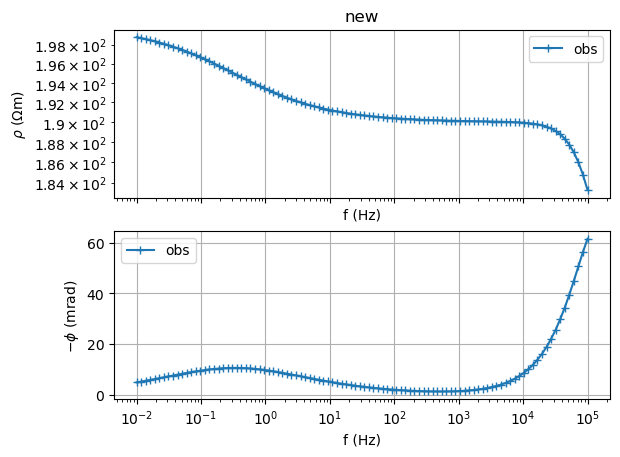

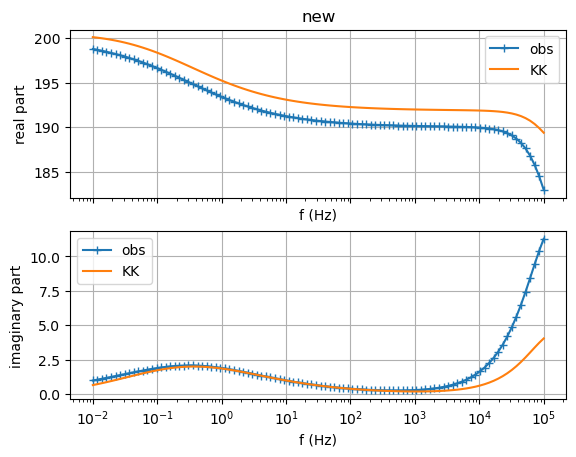

In [3]:
# generating synthetic data (double cole-cole method) with SIPspectrum obj (holds all data for the model)
f = np.logspace(-2, 5, 100)
Z1 = modelColeColeRho(f, rho=1, m=0.1, tau=0.5, c=0.5)
Z2 = modelColeColeRho(f, rho=1, m=0.25, tau=1e-6, c=1.0)

rho0 = 100 
Z = rho0 * (Z1 + Z2)

sip = SIPSpectrum(f=f, amp=np.abs(Z), phi=-np.angle(Z))

sip.showData()
sip.showDataKK()  # check Kramers-Kronig relations
# basically we are checking if it is geologically realistic

In [5]:
# the above is a synthetic data that we have made.. we will now compare it with the results from SIP sign. to calc. accuracy of model

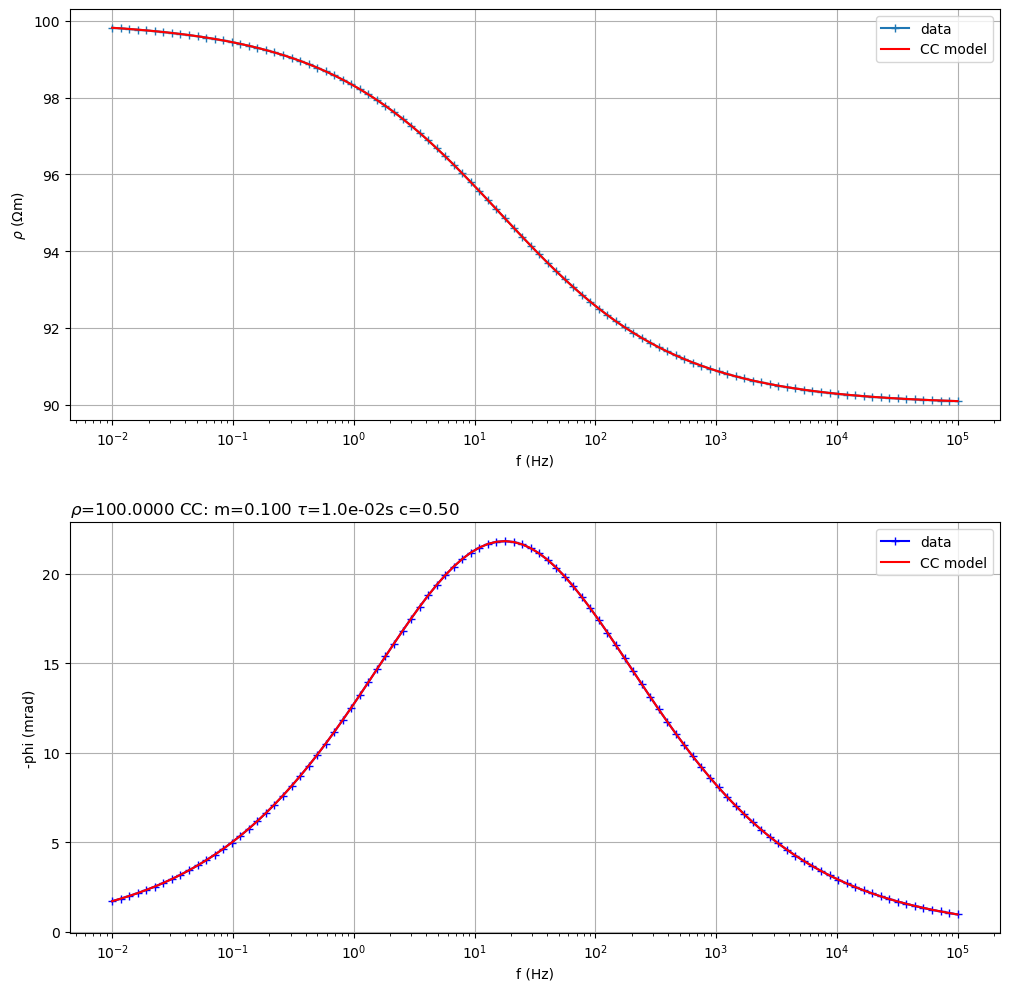

(<Figure size 1200x1200 with 2 Axes>,
 array([<Axes: xlabel='f (Hz)', ylabel='$\\rho$ ($\\Omega$m)'>,
        <Axes: title={'left': '$\\rho$=100.0000 CC: m=0.100 $\\tau$=1.0e-02s c=0.50 '}, xlabel='f (Hz)', ylabel='-phi (mrad)'>],
       dtype=object))

In [6]:
# fit a cole-cole model from synthetic data 

Z = modelColeColeRho(f, rho=100, m=0.1, tau=0.01, c=0.5)
#data need some noise

sip = SIPSpectrum(f=f, amp=np.abs(Z), phi=-np.angle(Z))
sip.fitColeCole(useCond=False, #fit based on R not 1/R
                verbose=False) #don't show working
# works for both rho and sigma models
sip.showAll()

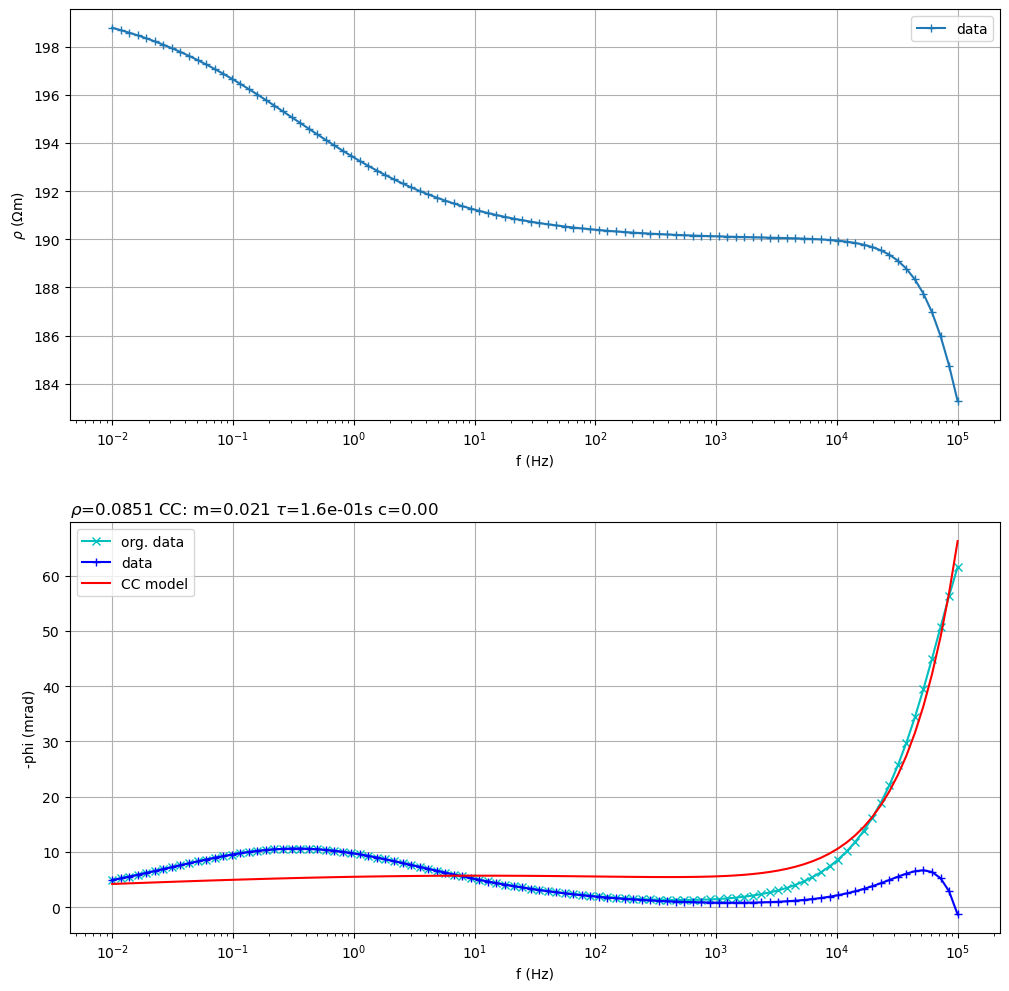

(<Figure size 1200x1200 with 2 Axes>,
 array([<Axes: xlabel='f (Hz)', ylabel='$\\rho$ ($\\Omega$m)'>,
        <Axes: title={'left': '$\\rho$=0.0851 CC: m=0.021 $\\tau$=1.6e-01s c=0.00 '}, xlabel='f (Hz)', ylabel='-phi (mrad)'>],
       dtype=object))

In [7]:
# fit the double cole cole model
f = np.logspace(-2, 5, 100)
Z1 = modelColeColeRho(f, rho=1, m=0.1, tau=0.5, c=0.5)
Z2 = modelColeColeRho(f, rho=1, m=0.25, tau=1e-6, c=1.0)

rho0 = 100 
Z = rho0 * (Z1 + Z2)

# TODO data need some noise
sip = SIPSpectrum(f=f, amp=np.abs(Z), phi=-np.angle(Z))
sip.fitCCEM(verbose=False) # 2 things : 1 cole-cole model(SIP term) & EM term (for electromagnetic coupling - fitting errors due to measurement setup)
sip.showAll()

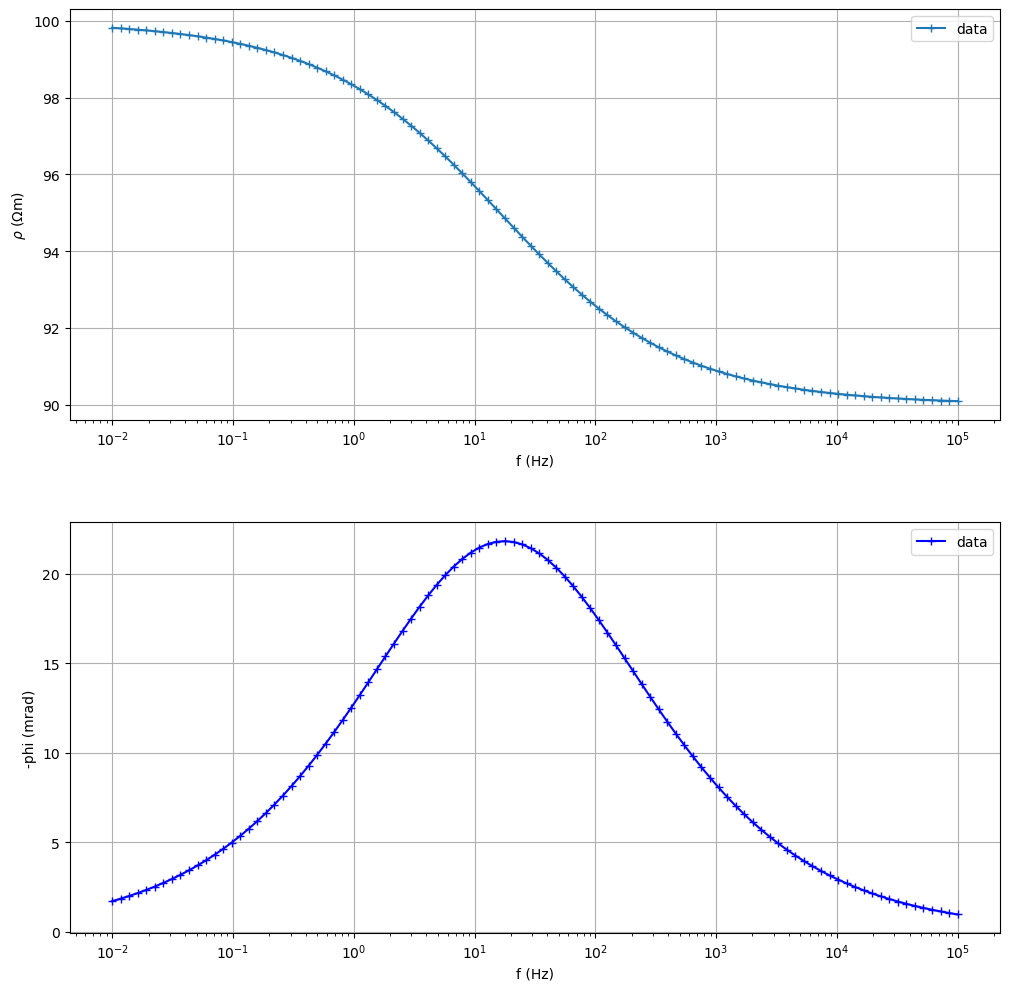

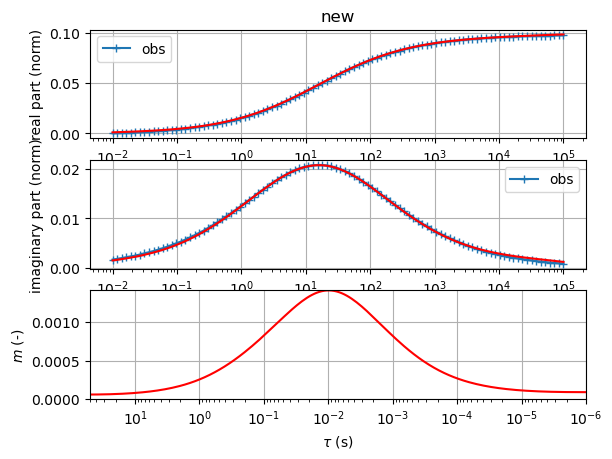

In [8]:
f = np.logspace(-2, 5, 100)
Z = modelColeColeRho(f, rho=100, m=0.1, tau=0.01, c=0.5)
sip = SIPSpectrum(f=f, amp=np.abs(Z), phi=-np.angle(Z))

sip.showAll()
sip.fitDebyeModel(new=True, showFit=True) #Debye decomposition (newer version)
pg.wait()